## 텐서플로우와 MNIST 데이터

In [5]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt

# MNIST 데이터 불러오기
mnist = keras.datasets.mnist
(train_images, train_labels), (test_images, test_labels) = \
mnist.load_data()

ModuleNotFoundError: No module named 'tensorflow'

In [ ]:
# 이미지 크기
print('train images/labels and test images/labels size')
print(train_images.shape, train_labels.shape,\
      test_images.shape, test_labels.shape)

train images/labels and test images/labels size
(60000, 28, 28) (60000,) (10000, 28, 28) (10000,)


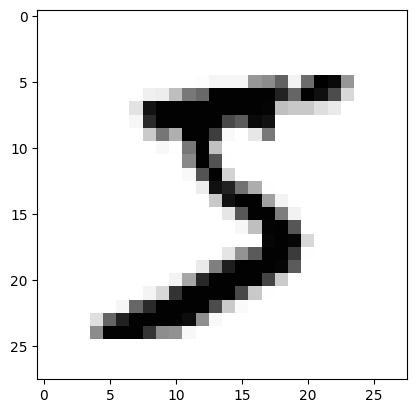

In [ ]:
# 이미지 출력
num = train_images[0] # 첫 번째 데이터
plt.imshow(num, cmap='Greys')

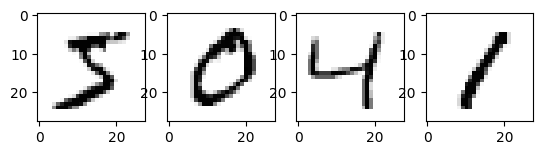

In [ ]:
fig = plt.figure()

for i in range(1, 5):
    ax = fig.add_subplot(1, 4, i)
    ax.imshow(train_images[i-1], cmap='Greys')

# 딥러닝 모델 만들고 학습시키기

In [ ]:
# 입력값 전처리
train_images, test_images = train_images/255, test_images/255

# 신경망 모델 만들기
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28, 28)),
    keras.layers.Dense(60, activation='relu'),
    keras.layers.Dense(10, activation='softmax')
])
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 60)             │        47,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           610 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 47,710 (186.37 KB)

 Trainable params: 47,710 (186.37 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [ ]:
model.fit(train_images, train_labels, epochs=3)

Epoch 1/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - accuracy: 0.9128 - loss: 0.3076
Epoch 2/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9554 - loss: 0.1498
Epoch 3/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9679 - loss: 0.1098


In [ ]:
test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=2)
print('테스트 정확도:', test_acc)

313/313 - 2s - 7ms/step - accuracy: 0.9658 - loss: 0.1131
테스트 정확도: 0.9657999873161316


In [ ]:
# 모델 테스트
pred = model.predict(test_images)
print(pred[0])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
[1.4679882e-05 3.3243865e-07 6.2001731e-05 5.0291832e-04 1.2374556e-07
 7.8456719e-07 5.7084248e-09 9.9936748e-01 2.6807875e-05 2.4805933e-05]


7


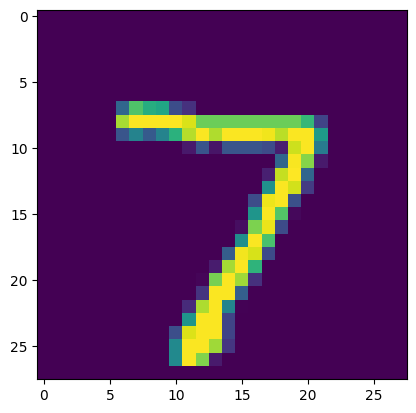

In [ ]:
print(test_labels[0])
plt.imshow(test_images[0])

## softmax 

In [ ]:
import numpy as np

def softmax(a):
    e_a = np.exp(a)
    sum_e = np.sum(e_a)
    y = e_a / sum_e
    return y

a = np.array([0.5, 4.1, 2.5, 5.6, 1.2])
print('예측값:', a)
print('소프트맥스 함수의 출력:', softmax(a))

예측값: [0.5 4.1 2.5 5.6 1.2]
소프트맥스 함수의 출력: [0.00473882 0.17343248 0.03501541 0.77727047 0.00954281]


In [ ]:
# 원-핫 인코딩
import numpy as np
from keras.utils import to_categorical

data = np.array([0, 1, 2, 3, 4])
print('원본:', data)

encoded = to_categorical(data)
print('원-핫 인코딩된 데이터')
print(encoded)

원본: [0 1 2 3 4]
원-핫 인코딩된 데이터
[[1. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 1.]]


In [ ]:
# 교차 엔트로피
def cee(y, t):
    delta = 1e-7
    return -np.sum(t * np.log(y+delta))

# 평균제곱 오차
def mse(y, t):
    return 1/len(y) * sum((y-t)**2)

t = np.array([0, 0, 1])
y_hat1 = np.array([0.4, 0.05, 0.55])
y_hat2 = np.array([0.9, 0.09, 0.01])

print(f'CEE of y_hat1: {cee(y_hat1, t):.2f}')
print(f'CEE of y_hat2: {cee(y_hat2, t):.2f}')
print(f'ratio of two CEE value: {cee(y_hat2, t) / cee(y_hat1, t):.2f}')

# y_hat 추정치와 정답과의 MSE
print(f'MSE of y_hat1: {mse(y_hat1, t):.2f}')
print(f'MSE of y_hat2: {mse(y_hat2, t):.2f}')
print(f'ratio of two MSE value: {mse(y_hat2, t) / mse(y_hat1, t):.2f}')

CEE of y_hat1: 0.60
CEE of y_hat2: 4.61
ratio of two CEE value: 7.70
MSE of y_hat1: 0.12
MSE of y_hat2: 0.60
ratio of two MSE value: 4.93
